# Session 16: Introduction to Deep Learning and Image Processing

**Learning goals:**

- Distinguish features, targets and model parameters, and explain training and inference.
- Explain how deeper networks build hierarchical representations.
- Relate algorithms, large datasets and computing hardware to the success of deep learning.
- Identify key contributors to deep learning and image recognition.
- Explain convolution, shared filters, stride, padding, pooling, fully connected layers and softmax.
- Compare LeNet-5, AlexNet, VGGNet and ResNet, including small filters and residual connections.
- Apply image filters and visualise MNIST digit images.
- Load labelled images, prepare batches and train a simple PyTorch CNN.
- Adapt a pretrained ResNet18 to a new set of classes by training a replacement head.
- Compare a scikit-learn MLP, a simple CNN and a pretrained ResNet18 on the same held-out images.

**Prerequisites:**

- Supervised learning, classification, train/test splits and model evaluation.
- Basic Python functions, classes, loops and NumPy arrays.
- Python with Pillow, Matplotlib, NumPy, scikit-learn, PyTorch and torchvision installed in the notebook environment.
- Internet access for the first download of the pretrained ResNet18 weights (about 45 MB).
- A GPU is optional; all practical examples can run on CPU.


## Outline

1. From machine learning to deep learning
2. Key scientists and contributors
3. CNN building blocks and image filtering
4. Popular CNN architectures
5. Why networks became deeper rather than only wider
6. Building and training CNN models with PyTorch
7. Transfer learning with a pretrained CNN
8. Compare an MLP, a simple CNN and a pretrained ResNet18


## 1. From Machine Learning to Deep Learning


### 1.1 Machine learning: learn from history

Machine learning (ML) builds a useful relationship from historical examples. In **supervised learning**, each example pairs **features** (the input measurements or attributes) with a known **target** (the value or class to predict). For digit recognition, the features are pixel values and the target is the digit label.

Instead of manually writing every rule, practitioners select a **method/algorithm** that learns the relationship between features and targets. Training uses the historical feature–target pairs to adjust **model parameters**, such as weights and biases. These parameters represent the learnt relationship between features and targets; they are different from the features and targets in the dataset.

During **inference**, the trained model receives features for a new case and produces a **predicted target**. The known target for that new case is not supplied as an input to the model.

![Historical features and known targets train model parameters that represent their relationship. The trained model maps new features to a predicted target.](images/ml-learning-from-history.svg){fig-alt="Historical feature–target pairs pass through a learning algorithm to produce parameters representing the relationship between features and targets. The trained model maps new features to a predicted target." style="width: 100%; height: auto;"}


### 1.2 Why add more layers?

A single layer can capture a limited transformation. Multiple layers can build a hierarchy: early layers detect simple patterns, middle layers combine them, and later layers form task-specific concepts. The CNN below illustrates the progression from edges and textures to outlines, shapes and a final class prediction.

![A dog image passes through CNN layers that learn edges, outlines, textures and shapes before a classifier predicts dog](images/cnn-dog-feature-extraction.png){fig-alt="A dog image passes through CNN layers that learn edges, outlines, textures and shapes before a classifier predicts dog" style="width: 100%; height: auto;"}

- **Early layers:** local edges and colour changes
- **Middle layers:** textures, contours and reusable parts
- **Later layers:** whole-object evidence and a task output


### 1.3 Why deep learning became successful

![Algorithms update network weights from errors, big data supplies many input-output examples, and a GPU processes matrix operations in parallel](images/why-deep-learning.svg){fig-alt="Three panels show error-driven weight updates, many historical input-output pairs, and parallel GPU matrix processing" style="width: 100%; height: auto;"}

- **Algorithms:** backpropagation, improved activation functions, optimisation methods and model architectures made deeper networks easier to train.
- **Big data:** more historical examples exposed useful patterns and supported models with greater capacity.
- **Higher-performance computing:** GPUs, specialised accelerators and distributed training made large-scale calculations practical.


## 2 - Key Scientists and Contributors

Modern image recognition is the result of many people and many research groups. The names below are useful starting points for students because each one connects to a different part of the story.

| Scientist | Why they matter for deep learning and image recognition |
|---|---|
| [Geoffrey Hinton](https://en.wikipedia.org/wiki/Geoffrey_Hinton) | Helped revive neural networks, popularised representation learning, co-authored the AlexNet paper, and contributed to backpropagation, Boltzmann machines, and knowledge distillation. |
| [Yann LeCun](https://en.wikipedia.org/wiki/Yann_LeCun) | Developed LeNet-style CNNs for handwritten digit recognition and made convolutional networks central to computer vision. |
| [Yoshua Bengio](https://en.wikipedia.org/wiki/Yoshua_Bengio) | Helped develop deep learning theory and representation learning, especially for training deep neural networks. |
| [Fei-Fei Li](https://en.wikipedia.org/wiki/Fei-Fei_Li) | Led work on ImageNet, a large labelled image dataset that helped make large-scale visual recognition measurable and competitive. |
| [Kunihiko Fukushima](https://en.wikipedia.org/wiki/Kunihiko_Fukushima) | Proposed the Neocognitron, an early biologically inspired model with ideas similar to later convolution and pooling. |
| [Jürgen Schmidhuber](https://en.wikipedia.org/wiki/J%C3%BCrgen_Schmidhuber) | Contributed to deep learning and recurrent networks, and his group worked on early GPU-accelerated neural networks. |
| [Kaiming He](https://en.wikipedia.org/wiki/Kaiming_He) | Co-authored ResNet and He initialisation, both important for training very deep networks. |

A useful way to read this history is not as one inventor story, but as a stack of ideas: datasets, compute, architectures, optimisation methods, and open-source tools all improved together.


## 3 - CNN Building Blocks

[Video: CNNs](https://www.youtube.com/watch?v=ip2HYPC_T9Q)


{{< video https://www.youtube.com/embed/ip2HYPC_T9Q?hl=en title="CNNs" aria-label="Video explaining convolutional neural networks" aspect-ratio="16x9" >}}


A CNN for image classification can be understood as four main parts. The early layers extract useful visual features; the final layers turn those features into a class prediction.

| Component | Role |
|---|---|
| **Convolutional layer** | Uses learnable filters to extract local features such as edges, corners, textures, and shapes. |
| **Pooling layer** | Shrinks feature maps while keeping the strongest or average signal in each local region. |
| **Fully connected layer** | Combines extracted features to produce class scores. |
| **Softmax** | Converts class scores into probabilities that sum to 1. |


### 3.1 CNN Network Structure

The diagram below shows a typical CNN flow: image input, repeated convolution and pooling, then fully connected layers and a final prediction.

![Typical CNN architecture](images/typical-cnn-architecture.png)

Interactive 3D demo: [Adam Harley - CNN 3D Visualisation](https://adamharley.com/nn_vis/cnn/3d.html). This visualisation shows how feature maps change as an image moves through a CNN.

Reference: inspired by [Pinecone - Visual Guide to Applied Convolution Neural Networks](https://www.pinecone.io/learn/series/image-search/cnn/). Images in this notebook are stored locally so they display offline.


### 3.2 Convolutional Layer: Filters Extract Features

A convolutional layer uses small filters to scan an image. Different filters respond to different visual patterns. For example, one filter may respond strongly to vertical edges, another to horizontal edges, and another to sharp outlines.

The animation below shows how a filter produces a feature map: the filter moves over the image, calculates one local response at a time, and builds a new representation for the next layer.

![Convolution filter producing a feature map](images/convolution-filter-feature-map.gif)


### 3.3 Convolutional Computing

At each image position, the filter and the image patch are multiplied element by element. The products are then added together. That one number becomes one value in the output feature map.

![Convolution element-wise multiplication](images/convolution-elementwise.png)

After this visual explanation, the next code cell applies several filters to the dog image to show how different filters highlight different features.


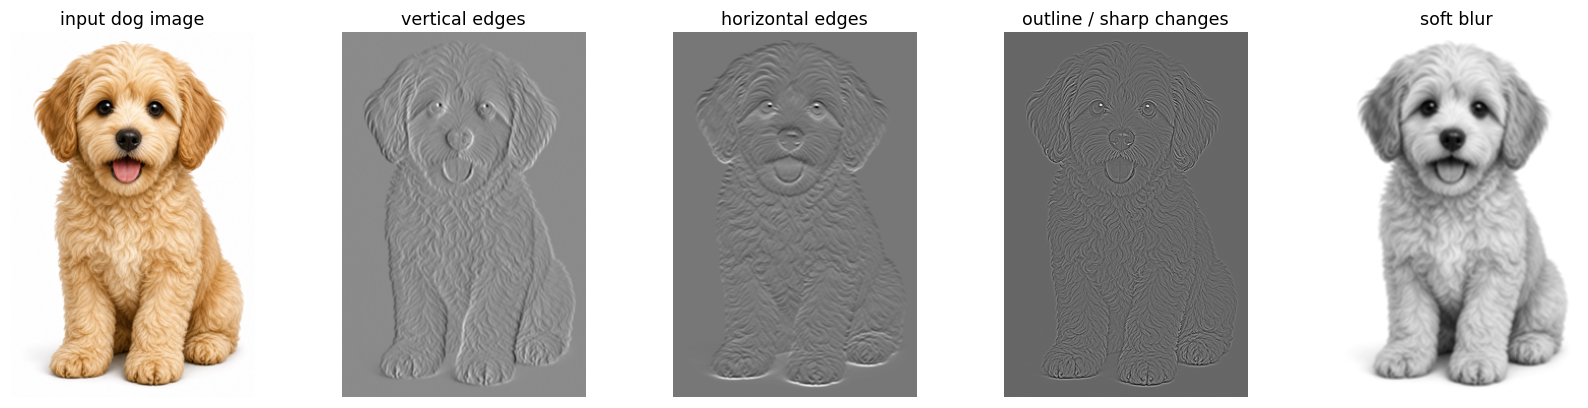

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

DOG_IMAGE = "images/dog_input.png"

# Load the image as RGB. Even though the filters below use greyscale, keeping the
# RGB version lets us display the original image beside the feature maps.
dog_rgb = Image.open(DOG_IMAGE).convert("RGB")

# Shrink the image so the nested loops below run quickly in a classroom notebook.
dog_rgb.thumbnail((360, 360))

# Convert image pixels from integers in [0, 255] to floats in [0, 1].
dog_rgb_array = np.asarray(dog_rgb, dtype=np.float32) / 255.0

# Convert RGB to greyscale using standard luminance weights.
# This gives one intensity value per pixel, which is easier for 2D filters.
dog_gray = (
    0.299 * dog_rgb_array[:, :, 0]
    + 0.587 * dog_rgb_array[:, :, 1]
    + 0.114 * dog_rgb_array[:, :, 2]
)

# Each small matrix below is a filter/kernel. Positive and negative values make
# the filter respond strongly to different patterns, such as edges or outlines.
filters = {
    "vertical edges": np.array(
        [
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1],
        ],
        dtype=np.float32,
    ),
    "horizontal edges": np.array(
        [
            [-1, -2, -1],
            [0, 0, 0],
            [1, 2, 1],
        ],
        dtype=np.float32,
    ),
    "outline / sharp changes": np.array(
        [
            [0, -1, 0],
            [-1, 4, -1],
            [0, -1, 0],
        ],
        dtype=np.float32,
    ),
    "soft blur": np.array(
        [
            [1, 1, 1],
            [1, 1, 1],
            [1, 1, 1],
        ],
        dtype=np.float32,
    ) / 9.0,
}


def apply_filter(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Apply a small 2D filter using edge padding."""
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    # Padding lets the filter still be centred on border pixels.
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="edge")
    output = np.zeros_like(image, dtype=np.float32)

    # Slide the filter over every pixel location.
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            # Extract the local image patch covered by the filter.
            patch = padded[row : row + kh, col : col + kw]

            # Element-wise multiply the patch and filter, then sum to one value.
            output[row, col] = np.sum(patch * kernel)

    return output


# Apply every filter and plot the resulting feature maps side by side.
feature_maps = {name: apply_filter(dog_gray, kernel) for name, kernel in filters.items()}

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(dog_rgb_array)
axes[0].set_title("input dog image")
axes[0].axis("off")

for ax, (name, feature_map) in zip(axes[1:], feature_maps.items()):
    ax.imshow(feature_map, cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()  # Display the original image and the filtered feature maps.


### 3.4 Stride and Padding

**Stride** controls how far the filter moves each step. A stride of `1` checks neighbouring positions; a stride of `2` skips one position each time and produces a smaller feature map.

![Convolution stride](images/convolution-stride.gif)

**Padding** adds extra pixels around the border before convolution. Padding helps the filter process edge pixels and can keep the output height and width closer to the input size.

![Convolution padding](images/convolution-padding.png)


### 3.5 Pooling Layer

Pooling compresses a small region into one value. In **max pooling**, the largest value is kept. In **average pooling**, the mean value is kept.

![Average vs max pooling](images/pooling-average-vs-max.png)

A small max-pooling example with a 2 by 2 window:

```text
Input region       Max pooling output

[1  3]
[2  4]       ->    4
```

A larger example with four non-overlapping 2 by 2 windows:

```text
Input feature map          Max-pooled feature map

[1  3  2  0]               [4  5]
[2  4  1  5]       ->      [8  7]
[0  1  7  3]
[6  8  2  4]
```


### 3.6 Fully Connected Layer and Softmax

After several convolution and pooling steps, the image has become a compact set of feature maps. These feature maps are flattened, or globally pooled, and then passed into a **fully connected classifier**.

A fully connected classifier is essentially an MLP-style classifier head: each neuron receives input from all values in the previous layer. It combines the extracted CNN features into class scores, also called **logits**.

![Fully connected layer](images/fully-connected-layer.png)

Softmax is usually applied after the final fully connected layer for multi-class classification. It converts logits into probabilities that sum to 1, so the largest probability becomes the predicted class.

![Softmax output](images/softmax-output.png)

A useful summary is:

```text
Convolution + pooling layers
-> extracted feature maps
-> flatten or global average pooling
-> fully connected classifier / MLP head
-> logits
-> softmax probabilities
-> predicted class
```

In PyTorch training code, the model often returns logits directly. `nn.CrossEntropyLoss()` then handles the softmax-like calculation internally, so we usually do not add an explicit `Softmax` layer before the loss.



## 4 - Popular Architectures

CNN image recognition developed rapidly after **AlexNet** won ILSVRC 2012 and greatly improved the state-of-the-art accuracy. Later architectures mainly improved depth, training stability, and computational efficiency.

![Evolution of CNN architectures](images/cnn-architecture-evolution.png)

| Architecture | Year | Typical depth | Approx. parameters | Key contributions |
|---|---:|---:|---:|---|
| **LeNet-5** | 1998 | 7 layers | ~60 thousand | Convolution, pooling, and fully connected classification. |
| **AlexNet** | 2012 | 8 layers | ~60 million | ReLU, dropout, GPU training, and ImageNet-scale training. |
| **VGGNet** | 2014 | 16 or 19 layers | ~138-143 million | Repeated small 3 by 3 filters to build deeper CNNs. |
| **ResNet** | 2015 | 18 to 152+ layers | ~11.7-60.2 million | Residual networks for training very deep CNNs. |


### 4.1 LeNet-5

LeNet-5 is an early CNN for handwritten digit recognition. It alternates convolution and pooling, then uses fully connected layers for classification.

![LeNet-5 architecture](images/lenet5-architecture.png)


### 4.2 AlexNet

AlexNet won ILSVRC 2012 and made large-scale CNN image classification a mainstream approach.

![AlexNet architecture](images/alexnet-architecture.png)

Key points:

- **ReLU** uses `ReLU(x) = max(0, x)`. It is simple, fast, and keeps stronger gradients for positive values.
- **Dropout** randomly sets some activations to zero during training, reducing overfitting in fully connected layers.
- **GPU training** made the large CNN practical to train on ImageNet.

Activation functions add non-linearity so that neural networks can learn complex patterns. Earlier networks often used sigmoid or tanh, but these functions can saturate and make gradients small.

![Activation functions](images/activation-functions.png)

The training curve below illustrates why ReLU became popular: it can reduce training error faster than tanh in deep CNNs.

![ReLU training advantage](images/relu-training-advantage.png)


### 4.3 VGGNet

VGGNet uses a simple deep structure based on repeated **3 by 3 convolutions**.

![VGGNet architecture](images/vggnet-architecture.png)

Key point: several small convolutions can replace one large convolution with fewer parameters and fewer multiply-add operations.

Ignoring bias terms, for a convolution with kernel size `k x k`, input channels `C_in`, output channels `C_out`, and output feature map size `H x W`:

$$
\text{parameters} = k^2 C_{in} C_{out}
$$

$$
\text{multiply-adds} \approx H W k^2 C_{in} C_{out}
$$

If `C_in = C_out = C`, one `5 x 5` convolution has:

$$
25C^2 \text{ parameters}, \quad HW \cdot 25C^2 \text{ multiply-adds}
$$

Two `3 x 3` convolutions have a similar receptive field but only:

$$
2 \times 9C^2 = 18C^2 \text{ parameters}, \quad HW \cdot 18C^2 \text{ multiply-adds}
$$

So the small-filter design reduces cost and adds an extra ReLU, giving the network more feature transformations.


### 4.4 ResNet

ResNet's key contribution is the **residual network**, which made very deep CNNs practical to train.

![ResNet architecture](images/resnet-architecture.png)

As CNNs become deeper, gradients can become very small when they are backpropagated through many layers. This **vanishing gradient** problem makes early layers learn slowly, and adding more layers can even make training accuracy worse.

A residual block adds a shortcut connection:

$$
\mathbf{y} = F(\mathbf{x}) + \mathbf{x}
$$

The shortcut gives gradients a more direct path back through the network. Instead of learning a full mapping from scratch, the block only needs to learn the correction `F(x)`. If extra layers are not useful, the block can learn a near-zero correction and pass the input forward.

**Batch Normalisation** normalises activations during training, then learns a scale and shift. It stabilises training and helps deep networks use larger learning rates.


## 5 - Why Did Networks Become Deeper Rather Than Only Wider?

1. **From local to global image understanding**: shallow convolutional layers have small receptive fields and learn local features such as edges, corners, and textures. Deeper layers combine features from earlier layers, so the representation becomes more abstract and specific: early layers may detect animal-like patterns, later layers may recognise a dog, and still deeper layers may separate breeds such as Husky or Staffordshire Bull Terrier.

2. **Fewer weights by trading width for depth**: multiple small convolutions can replace one large convolution. For example, two `3 x 3` convolutions can cover a similar area to one `5 x 5` convolution, but use fewer weights and add more non-linear feature transformations.

3. **Trainable deep networks**: residual networks use shortcut connections to reduce vanishing-gradient problems, making much deeper CNNs practical to train.

4. **GPU acceleration**: convolution is highly parallel, so GPUs make large CNN training much faster than CPUs.


## 6. Building and Training CNN Models with PyTorch

We will train a small CNN to recognise handwritten digits from 0 to 9. The dataset contains 240 labelled PNGs, with 24 images per digit. In Section 7, we will reuse the same training and test images with a pretrained model.

[Download the digit images ZIP](sample_data/digit_images.zip){download="digit_images.zip"} · [Download the practice notebook](<practice/Practice CNN Training with PyTorch.ipynb>){download="Practice CNN Training with PyTorch.ipynb"} · [Open in Colab](https://colab.research.google.com/github/wlos/ai_with_python_course/blob/main/16-Deep-Learning-and-Image-Processing/practice/Practice%20CNN%20Training%20with%20PyTorch.ipynb)

### 6.1 Loading Images with Datasets and Transforms

Download `digit_images.zip` using the link above. In Colab, upload the ZIP to the runtime's working directory using the **Files** panel. In a new Colab cell, enter `!unzip -q digit_images.zip` and run it.

If you are running Jupyter from a local course checkout, open a terminal in the Session 16 folder and run:

```bash
unzip -q sample_data/digit_images.zip
```

Both commands create `sample_data/digit_images/` in the working directory. Check that it contains class folders `0` to `9` before running the Python cell.

`ImageFolder` assigns a class index to each class folder in alphabetical order. Here the folder names are the digits `0` to `9`, so the class indices match the digits. Each time you retrieve a sample, the dataset opens the image and runs the transforms in order. The result is one greyscale tensor of shape `(1, 28, 28)` and its class index.

![From image files to CNN inputs](images/session13-image-to-cnn-pipeline.png){fig-alt="Image files become resized greyscale tensors, then form a batch for the CNN."}

[torchvision ImageFolder documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html)


In [ ]:
from torchvision import datasets, transforms

DIGIT_ROOT = "sample_data/digit_images"

digit_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),  # Use one intensity channel.
    transforms.Resize((28, 28)),  # Give every image the same size.
    transforms.ToTensor(),  # Scale 8-bit pixels to [0, 1] in (C, H, W) order.
])
digit_dataset = datasets.ImageFolder(DIGIT_ROOT, transform=digit_transform)
sample_image, sample_label = digit_dataset[0]
print(f"Images: {len(digit_dataset)} | Classes: {digit_dataset.class_to_idx}")
print(f"One image: {tuple(sample_image.shape)} | Label: {sample_label}")


Images: 240 | Classes: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9}
One image: (1, 28, 28) | Label: 0


### 6.2 Preparing Image Batches

Use PyTorch's `random_split` to reserve 80% of the images for training and 20% for testing. A fixed seed reproduces the same split. The split selects images at random, so the proportions of individual digits can vary between subsets. A `DataLoader` stacks individual samples into batches of images with shape `(N, C, H, W)` and labels with shape `(N,)`. Here, `N` is the number of images in the current batch, which may be smaller for the final batch. Shuffle the training images each epoch and keep the test order fixed.

![How DataLoader groups labelled images](images/session13-dataloader-batches.png){fig-alt="Labelled images are shuffled into batches, keeping each image paired with its label."}


In [ ]:
import torch
from torch.utils.data import DataLoader, random_split

DIGIT_SEED = 42

# Randomly assign each image to exactly one subset using a fixed seed.
train_size = int(0.8 * len(digit_dataset))
test_size = len(digit_dataset) - train_size
torch.manual_seed(DIGIT_SEED)
digit_train, digit_test = random_split(
    digit_dataset,
    [train_size, test_size],
)
digit_train_loader = DataLoader(
    digit_train, batch_size=16, shuffle=True,
)
digit_test_loader = DataLoader(digit_test, batch_size=16, shuffle=False)

batch_images, batch_labels = next(iter(digit_test_loader))
print(f"Training images: {len(digit_train)} | Test images: {len(digit_test)}")
print(f"Image batch: {tuple(batch_images.shape)} | Label batch: {tuple(batch_labels.shape)}")
print(f"Batch labels: {batch_labels.tolist()}")


Training images: 192 | Test images: 48
Image batch: (16, 1, 28, 28) | Label batch: (16,)
Batch labels: [6, 7, 3, 9, 1, 6, 5, 8, 6, 8, 2, 6, 4, 6, 3, 3]


### 6.3 Build a Simple CNN with Conv2d and MaxPool2d

The CNN applies two blocks in order. Each block uses a 3 × 3 convolution with padding 1 and stride 1 to keep the spatial dimensions, applies ReLU to set negative responses to zero, then uses 2 × 2 max pooling to halve the height and width.

- The first block takes one greyscale channel and produces eight feature maps of size 14 × 14 after pooling.
- The second block takes those eight maps and produces 16 feature maps of size 7 × 7 after pooling.

Flatten the 16 pooled maps and pass the resulting 784 values per image to a linear layer. It returns one logit, or unnormalised score, per digit.


In [ ]:
from torch import nn

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

class DigitCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 28 × 28 to 14 × 14.
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 14 × 14 to 7 × 7.
        )
        self.flatten = nn.Flatten()  # Keep the batch dimension separate.
        self.head = nn.Linear(16 * 7 * 7, num_classes)

    def forward(self, images):
        features = self.features(images)
        return self.head(self.flatten(features))

torch.manual_seed(DIGIT_SEED)  # Reproduce the model's initial weights.
digit_class_count = len(digit_dataset.classes)
digit_cnn = DigitCNN(digit_class_count).to(DEVICE)


### 6.4 Train the CNN

An **epoch** is one pass through the training set. Set training mode before the epoch loop. Within each epoch, repeat the five training steps for every batch, then report the mean loss and training accuracy.

![CNN training flowchart](images/cnn-training-workflow.png){fig-alt="Set training mode, start an epoch and train on one batch. Repeat the batch step while batches remain. Then report the mean epoch loss and start the next epoch if one remains. Otherwise training is complete."}

| Operation | What it does |
| --- | --- |
| `digit_cnn.train()` | Selects training behaviour for layers such as Dropout and BatchNorm. The `for` loops control the training run. |
| `torch.optim.Adam(digit_cnn.parameters(), lr=...)` | Creates the optimiser and sets its learning rate. |
| `optimiser.zero_grad()` | Clears gradients left by the previous batch so they do not accumulate. |
| `model(images)` | Runs the forward pass to produce one set of class logits per image. |
| `digit_loss(model(images), labels)` | Uses `nn.CrossEntropyLoss()` to compare raw logits with integer class labels. It applies log-softmax internally. |
| `loss.backward()` | Calculates gradients for the trainable parameters. |
| `optimiser.step()` | Updates the parameters using the gradients calculated for this batch. |



In [ ]:
DIGIT_EPOCHS = 10
DIGIT_LEARNING_RATE = 0.001
digit_loss = nn.CrossEntropyLoss()

def train_digit_epoch(model, loader, optimiser):
    '''Train for one epoch and return mean loss and accuracy.'''
    total_loss = 0.0
    correct = 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimiser.zero_grad()  # Clear gradients left by the previous batch.
        logits = model(images)
        loss = digit_loss(logits, labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        loss.backward()  # Calculate gradients from the loss.
        optimiser.step()  # Apply an update to the optimiser's parameters.
        total_loss += loss.item() * len(labels)  # Weight each batch by its size.
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

digit_optimiser = torch.optim.Adam(digit_cnn.parameters(), lr=DIGIT_LEARNING_RATE)
digit_cnn.train()
cnn_training_losses = []
cnn_training_accuracies = []
for epoch in range(DIGIT_EPOCHS):
    mean_loss, train_accuracy = train_digit_epoch(digit_cnn, digit_train_loader, digit_optimiser)
    cnn_training_losses.append(mean_loss)
    cnn_training_accuracies.append(train_accuracy)
    print(f"Simple CNN epoch {epoch + 1}: loss={mean_loss:.3f} | accuracy={train_accuracy:.1%}")


Simple CNN epoch 1: loss=2.305 | accuracy=11.5%
Simple CNN epoch 2: loss=2.212 | accuracy=27.6%
Simple CNN epoch 3: loss=2.036 | accuracy=42.2%
Simple CNN epoch 4: loss=1.727 | accuracy=67.7%
Simple CNN epoch 5: loss=1.302 | accuracy=78.1%
Simple CNN epoch 6: loss=0.890 | accuracy=82.8%
Simple CNN epoch 7: loss=0.661 | accuracy=81.8%
Simple CNN epoch 8: loss=0.517 | accuracy=84.9%
Simple CNN epoch 9: loss=0.415 | accuracy=90.1%
Simple CNN epoch 10: loss=0.359 | accuracy=90.1%


**Learning Curve**

A learning curve shows how a metric changes as training progresses. The left plot tracks mean training loss and the right plot tracks training accuracy across epochs. Training accuracy uses the predictions made before each batch's weight update. The next section evaluates the trained model on held-out images.


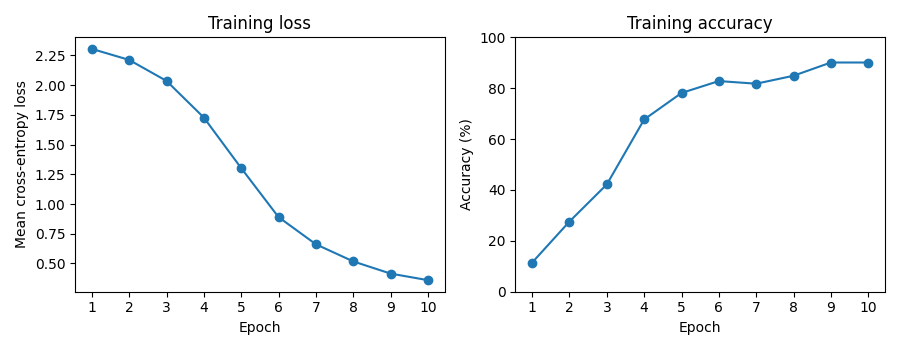

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(cnn_training_losses) + 1)
figure, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(epochs, cnn_training_losses, marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Mean cross-entropy loss", xticks=list(epochs))
axes[1].plot(epochs, [100 * accuracy for accuracy in cnn_training_accuracies], marker="o")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy (%)", xticks=list(epochs), ylim=(0, 100))

figure.tight_layout()
plt.show()


### 6.5 Test and Evaluate the CNN

Run the trained model on the entire test set in evaluation mode. For each image, choose the class with the largest logit and save its true label and prediction. Then use scikit-learn to calculate overall test accuracy.


In [ ]:
def predict_digits(model, loader):
    """Return true and predicted class indices in test-loader order."""
    model.eval()
    true_labels = []
    predictions = []
    with torch.no_grad():  # Inference does not need gradients.
        for images, labels in loader:
            logits = model(images.to(DEVICE))
            true_labels.extend(labels.tolist())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
    return true_labels, predictions

cnn_test_labels, cnn_test_predictions = predict_digits(digit_cnn, digit_test_loader)
print(f"Test predictions: {len(cnn_test_predictions)}")


Test predictions: 48


In [ ]:
from sklearn.metrics import accuracy_score

simple_digit_accuracy = accuracy_score(cnn_test_labels, cnn_test_predictions)
print(f"Simple CNN test accuracy: {simple_digit_accuracy:.1%}")


Simple CNN test accuracy: 81.2%


The grid shows the first eight test images in test-loader order, with the true and predicted digit above each image. Compare the predictions with the original images.


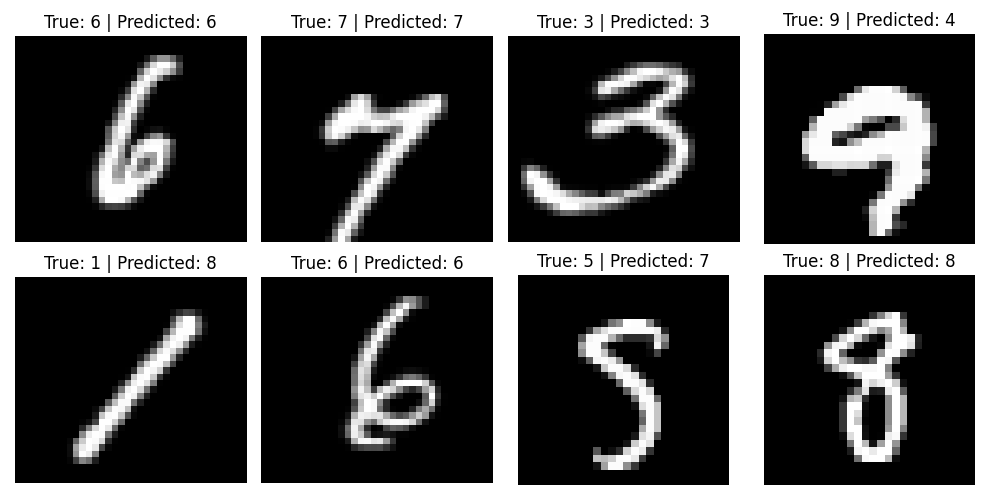

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

figure, axes = plt.subplots(2, 4, figsize=(10, 5))
for index, axis in enumerate(axes.flat):
    # Look up the original file using the same order as the test predictions.
    image_path, _ = digit_dataset.samples[digit_test.indices[index]]
    with Image.open(image_path) as image:
        axis.imshow(image.convert("L"), cmap="gray")
    axis.set_title(f"True: {cnn_test_labels[index]} | Predicted: {cnn_test_predictions[index]}")
    axis.axis("off")

figure.tight_layout()
plt.show()


## 7. Transfer Learning with a Pretrained CNN

Transfer learning starts with weights learned on an earlier task. ResNet18 has learned visual features from ImageNet, including edges, textures and shapes. We keep its feature extractor (the **backbone**) frozen and train a new **classification head** for digits. If the new task needs different features, **fine-tuning** lets selected pretrained layers learn as well.

![Transfer learning with ResNet18](images/transfer-learning-workflow.svg){fig-alt="Load pretrained ResNet18, replace its head and prepare inputs. Configure gradients, the optimiser and layer modes before training the replacement head."}

[PyTorch transfer learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) · [ResNet18 weights and preprocessing](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

[Download the practice notebook](<practice/Practice Transfer Learning with ResNet18.ipynb>){download="Practice Transfer Learning with ResNet18.ipynb"} · [Open in Colab](https://colab.research.google.com/github/wlos/ai_with_python_course/blob/main/16-Deep-Learning-and-Image-Processing/practice/Practice%20Transfer%20Learning%20with%20ResNet18.ipynb)

### 7.1 Prepare Images for the Pretrained Model

Import the `models` module from torchvision and select the default ResNet18 weights with `models.ResNet18_Weights.DEFAULT`. The selected weights also provide the input transform.

ResNet18's pretrained weights expect three-channel images with the size and normalisation used for ImageNet. `ImageFolder` opens these PNGs as RGB by default. The transform supplied with the weights resizes the images, takes a 224 × 224 centre crop and normalises the three channels. Before running this section, extract the digit ZIP as described in Section 6.1. The code below opens the extracted directory directly. Reset the PyTorch seed before `random_split` and use the same 80/20 split as Section 6 so the models use the same images.


In [ ]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, models

DIGIT_ROOT = "sample_data/digit_images"
DIGIT_SEED = 42

resnet_weights = models.ResNet18_Weights.DEFAULT
resnet_digit_dataset = datasets.ImageFolder(
    DIGIT_ROOT, transform=resnet_weights.transforms()
)
# Recreate the same split for the ResNet18 input transform.
train_size = int(0.8 * len(resnet_digit_dataset))
test_size = len(resnet_digit_dataset) - train_size
torch.manual_seed(DIGIT_SEED)
resnet_train, resnet_test = random_split(
    resnet_digit_dataset,
    [train_size, test_size],
)
resnet_train_loader = DataLoader(
    resnet_train,
    batch_size=16,
    shuffle=True,
)
resnet_test_loader = DataLoader(
    resnet_test,
    batch_size=16,
    shuffle=False,
)
resnet_image, _ = resnet_digit_dataset[0]
print(f"One ResNet18 input: {tuple(resnet_image.shape)}")


One ResNet18 input: (3, 224, 224)


### 7.2 Freeze the Backbone and Replace the Head

Build the model with `models.resnet18(weights=resnet_weights)`. The first call downloads the selected weights. Freeze the existing parameters with `requires_grad_(False)`, then replace the ImageNet classifier with a new linear layer that returns ten logits. Give the optimiser only the new head's parameters.

Set the whole model to evaluation mode to keep the backbone's BatchNorm running statistics fixed. Then put just the head into training mode. Parameter gradients and layer modes are separate settings. If you later fine-tune a backbone layer, enable its gradients, include its parameters in the optimiser and choose its layer mode.


In [ ]:
from torch import nn

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
RESNET_LEARNING_RATE = 0.001

torch.manual_seed(DIGIT_SEED)
digit_resnet = models.resnet18(weights=resnet_weights)
digit_resnet.requires_grad_(False)  # Freeze all original pretrained parameters.
digit_resnet.fc = nn.Linear(
    digit_resnet.fc.in_features, len(resnet_digit_dataset.classes)
)
digit_resnet = digit_resnet.to(DEVICE)
digit_resnet.eval()  # Preserve the backbone's BatchNorm running statistics.
digit_resnet.fc.train()  # Set training mode only for the replacement head.
resnet_optimiser = torch.optim.Adam(digit_resnet.fc.parameters(), lr=RESNET_LEARNING_RATE)
print(f"Trainable head parameters: {sum(p.numel() for p in digit_resnet.fc.parameters()):,}")


Trainable head parameters: 5,130


### 7.3 Train the Classification Head

Use the same batch training steps as in Section 6. Each forward pass still runs the full ResNet18 backbone. Only the new head's parameters receive updates.


In [ ]:
RESNET_EPOCHS = 10
resnet_loss = nn.CrossEntropyLoss()

digit_resnet.eval()  # Keep the frozen backbone in evaluation mode.
digit_resnet.fc.train()
resnet_training_losses = []
resnet_training_accuracies = []
for epoch in range(RESNET_EPOCHS):
    total_loss = 0.0
    correct = 0
    for images, labels in resnet_train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        resnet_optimiser.zero_grad()  # Clear gradients from the previous batch.
        logits = digit_resnet(images)
        loss = resnet_loss(logits, labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        loss.backward()
        resnet_optimiser.step()  # Update the replacement head.
        total_loss += loss.item() * len(labels)
    mean_loss = total_loss / len(resnet_train_loader.dataset)
    train_accuracy = correct / len(resnet_train_loader.dataset)
    resnet_training_losses.append(mean_loss)
    resnet_training_accuracies.append(train_accuracy)
    print(f"ResNet18 head epoch {epoch + 1}: loss={mean_loss:.3f} | accuracy={train_accuracy:.1%}")


ResNet18 head epoch 1: loss=2.290 | accuracy=13.5%
ResNet18 head epoch 2: loss=1.872 | accuracy=41.7%
ResNet18 head epoch 3: loss=1.548 | accuracy=69.3%
ResNet18 head epoch 4: loss=1.317 | accuracy=77.6%
ResNet18 head epoch 5: loss=1.117 | accuracy=85.9%
ResNet18 head epoch 6: loss=0.957 | accuracy=89.6%
ResNet18 head epoch 7: loss=0.850 | accuracy=88.0%
ResNet18 head epoch 8: loss=0.753 | accuracy=91.7%
ResNet18 head epoch 9: loss=0.675 | accuracy=93.2%
ResNet18 head epoch 10: loss=0.613 | accuracy=93.8%


**Learning Curve**

Read the ResNet18 learning curves the same way as in Section 6. The left plot shows mean training loss and the right plot shows training accuracy as the replacement head learns across epochs. The next section evaluates the trained model on held-out images.


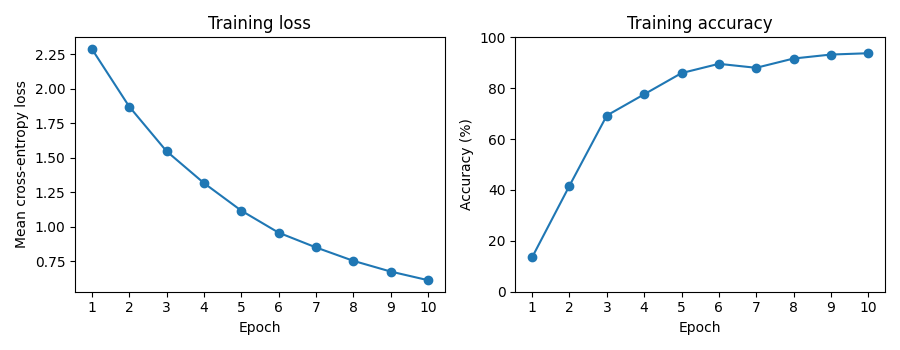

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(resnet_training_losses) + 1)
figure, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(epochs, resnet_training_losses, marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Mean cross-entropy loss", xticks=list(epochs))
axes[1].plot(epochs, [100 * accuracy for accuracy in resnet_training_accuracies], marker="o")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy (%)", xticks=list(epochs), ylim=(0, 100))

figure.tight_layout()
plt.show()


### 7.4 Test and Compare the Models

Collect the ResNet18 predictions on the same held-out images as the simple CNN. Use scikit-learn to calculate overall test accuracy. If you also ran Section 6, compare the two accuracies and look for differences in the example predictions.


In [ ]:
digit_resnet.eval()
resnet_test_labels = []
resnet_test_predictions = []
with torch.no_grad():  # Collect predictions without tracking gradients.
    for images, labels in resnet_test_loader:
        logits = digit_resnet(images.to(DEVICE))
        resnet_test_labels.extend(labels.tolist())
        resnet_test_predictions.extend(logits.argmax(dim=1).cpu().tolist())

print(f"Test predictions: {len(resnet_test_predictions)}")


Test predictions: 48


In [ ]:
from sklearn.metrics import accuracy_score

resnet_digit_accuracy = accuracy_score(resnet_test_labels, resnet_test_predictions)
print(f"Frozen ResNet18 test accuracy: {resnet_digit_accuracy:.1%}")


Frozen ResNet18 test accuracy: 83.3%


The grid shows the first eight test images in test-loader order, with the true and predicted digit above each image. Compare the predictions with the original images.


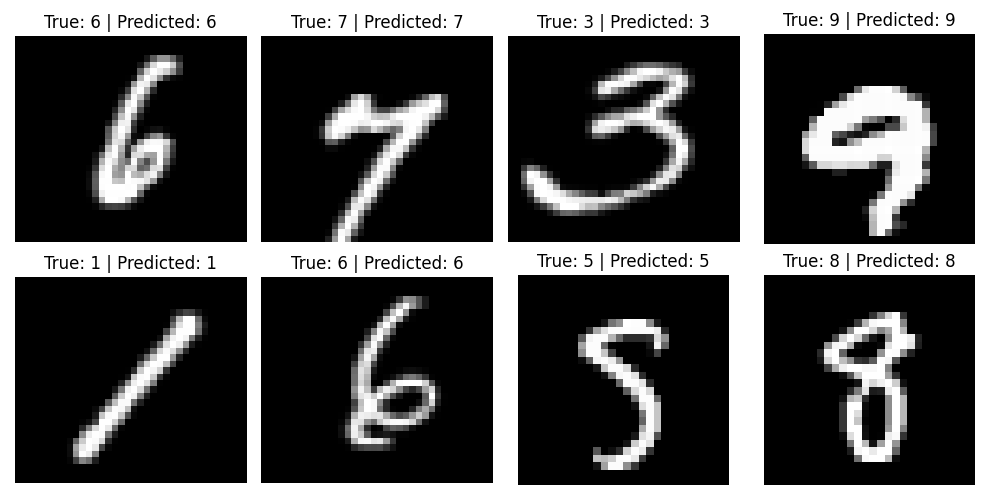

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

figure, axes = plt.subplots(2, 4, figsize=(10, 5))
for index, axis in enumerate(axes.flat):
    # Look up the original file using the same order as the test predictions.
    image_path, _ = resnet_digit_dataset.samples[resnet_test.indices[index]]
    with Image.open(image_path) as image:
        axis.imshow(image.convert("L"), cmap="gray")
    axis.set_title(f"True: {resnet_test_labels[index]} | Predicted: {resnet_test_predictions[index]}")
    axis.axis("off")

figure.tight_layout()
plt.show()


### 7.5 Save and Reuse the Trained Model

Save the model's `state_dict`, which contains its trained parameters and buffers, including BatchNorm running statistics. Also save the class names in output order and the name of the pretrained weights so the same image transform can be recovered later.

The file `resnet18_digits.pth` is written to the current working directory. In Colab, download it from the **Files** panel to keep it after the runtime ends.


In [ ]:
MODEL_FILE = "resnet18_digits.pth"

torch.save({
    "model_state_dict": digit_resnet.state_dict(),
    "class_names": resnet_digit_dataset.classes,
    "preprocessing_weights": resnet_weights.name,
}, MODEL_FILE)
print(f"Saved model to {MODEL_FILE}")


Saved model to resnet18_digits.pth


To classify an image in a fresh session, place the saved file and the example image at the paths below. Recreate the ResNet18 architecture with the same number of outputs, then load the saved state onto the CPU. `weights=None` creates the architecture without downloading ImageNet weights. Apply the saved preprocessing and add a batch dimension before making the prediction.

[PyTorch guide to saving and loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)


In [ ]:
import torch
from PIL import Image
from torch import nn
from torchvision import models

MODEL_FILE = "resnet18_digits.pth"
IMAGE_FILE = "sample_data/digit_images/0/mnist-row-00106.png"

checkpoint = torch.load(MODEL_FILE, map_location="cpu", weights_only=True)
class_names = checkpoint["class_names"]
restored_resnet = models.resnet18(weights=None)
restored_resnet.fc = nn.Linear(restored_resnet.fc.in_features, len(class_names))
restored_resnet.load_state_dict(checkpoint["model_state_dict"])
restored_resnet.eval()  # Use the saved BatchNorm statistics.

weights = models.ResNet18_Weights[checkpoint["preprocessing_weights"]]
with Image.open(IMAGE_FILE) as image:
    image_batch = weights.transforms()(image.convert("RGB")).unsqueeze(0)

with torch.no_grad():
    predicted_index = restored_resnet(image_batch).argmax(dim=1).item()
print(f"Predicted digit: {class_names[predicted_index]}")


Predicted digit: 0


## 8. Compare an MLP, a Simple CNN and a Pretrained ResNet18 {#image-classification-with-scikit-learn-and-a-cnn}

Use the same 240 digit images and the same 192-image training set and 48-image test set as Sections 6 and 7. Run those sections first so their test accuracies are available. Here we train and test a scikit-learn multilayer perceptron (MLP), then compare its accuracy with the results already recorded for the simple CNN and ResNet18.

[Download the practice notebook](<practice/Practice MNIST Image Classification.ipynb>){download="Practice MNIST Image Classification.ipynb"} · [Open in Colab](https://colab.research.google.com/github/wlos/ai_with_python_course/blob/main/16-Deep-Learning-and-Image-Processing/practice/Practice%20MNIST%20Image%20Classification.ipynb)


### 8.1 Train the MLP

The MLP receives each greyscale image as a row of 784 pixel values. It uses the images and labels from `digit_train` in Section 6. The scikit-learn MLP uses one hidden layer of 64 units and manages the training loop inside `fit()`.


In [ ]:
import numpy as np
from sklearn.neural_network import MLPClassifier

def flatten_digit_images(dataset):
    """Turn each greyscale image into a row of pixel values."""
    pixels, labels = [], []
    for image, label in dataset:
        pixels.append(image.flatten().numpy())
        labels.append(label)
    return np.stack(pixels), labels

mlp_train_pixels, mlp_train_labels = flatten_digit_images(digit_train)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64,), max_iter=300, random_state=DIGIT_SEED,
)
mlp_model.fit(mlp_train_pixels, mlp_train_labels)
print(f"Training input shape: {mlp_train_pixels.shape}")


Training input shape: (192, 784)


### 8.2 Test the MLP

Flatten the images in `digit_test` the same way. Use `predict()` to classify them, then calculate accuracy against their true labels.


In [ ]:
from sklearn.metrics import accuracy_score

mlp_test_pixels, mlp_test_labels = flatten_digit_images(digit_test)
mlp_test_predictions = mlp_model.predict(mlp_test_pixels)
mlp_test_accuracy = accuracy_score(mlp_test_labels, mlp_test_predictions)
print(f"MLP test accuracy: {mlp_test_accuracy:.1%} on {len(mlp_test_labels)} images")


MLP test accuracy: 77.1% on 48 images


### 8.3 Compare the Three Models

The simple CNN uses 28 × 28 greyscale tensors and learns its filters from the training images. ResNet18 uses its ImageNet preprocessing and trains a replacement head. All three accuracies below refer to the same 48 test images. Use the model designs and the small test set to explain how you would interpret the differences.


In [ ]:
print(f"MLP test accuracy: {mlp_test_accuracy:.1%}")
print(f"Simple CNN test accuracy: {simple_digit_accuracy:.1%}")
print(f"ResNet18 test accuracy: {resnet_digit_accuracy:.1%}")


MLP test accuracy: 77.1%
Simple CNN test accuracy: 81.2%
ResNet18 test accuracy: 83.3%
